### Boston Housing EDA

### 1. What is EDA
EDA = look at the table before you marry it.

Questions EDA answers cheaply:

How many rows? What columns?
What is the target (MEDV = median home value in $1000s)?
Which columns are numbers vs categories?
Any missing values?
Does river view (CHAS) or room count (RM) shout in the plots?
Skip EDA and the model will still run. It might learn that row 47 is special because it is row 47.

Target (Y): MEDV — median house price in thousands of dollars.

Example: MEDV = 24.0 means about $24,000 (dataset is old; do not move to Boston with this budget).

Categorical (for us today): CHAS (0/1 = not on Charles River / on river).
Numeric stars: RM (rooms), LSTAT (% lower status), NOX, AGE, etc.

### 2. Analytical view of a dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Importing completed!")

Importing completed!


In [3]:
df = pd.read_csv('housing_selected.csv')
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,4.0900,1,296.0,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,4.9671,2,242.0,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,4.9671,2,242.0,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,6.0622,3,222.0,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,6.0622,3,222.0,18.7,5.33,36.2


In [4]:
print(f"Total potential features: {df.shape[1]}")
print(f"Total samples: {df.shape[0]}")

Total potential features: 12
Total samples: 506


### 3. Input screening

In [5]:
df.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
DIS        0
RAD        0
TAX        0
PTRATIO    0
LSTAT      0
MEDV       0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

no nulls or duplicates found

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 12 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   DIS      506 non-null    float64
 7   RAD      506 non-null    int64  
 8   TAX      506 non-null    float64
 9   PTRATIO  506 non-null    float64
 10  LSTAT    506 non-null    float64
 11  MEDV     506 non-null    float64
dtypes: float64(10), int64(2)
memory usage: 47.6 KB


In CHAS it should be value counts just 0 and 1

In [9]:
display(df['CHAS'].value_counts())

CHAS
0    471
1     35
Name: count, dtype: int64

### 4. Statistical profiling

In [10]:
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


treating chas as a category

In [12]:
df['CHAS'].value_counts(normalize=True).round(2)

CHAS
0    0.93
1    0.07
Name: proportion, dtype: float64

### 5. Univariate — categorical (CHAS)

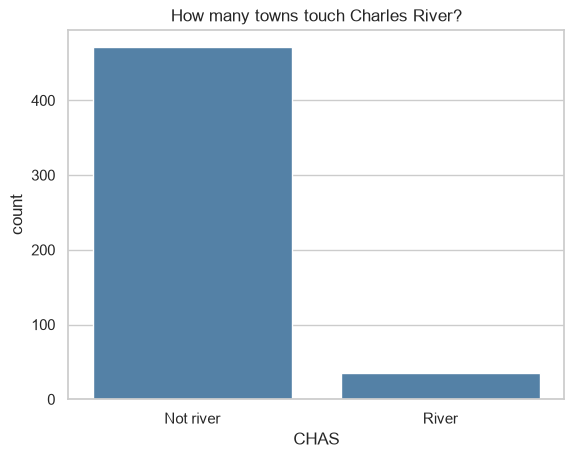

In [14]:
sns.countplot(data=df, x='CHAS', color='steelblue')
plt.xticks([0,1], ['Not river', 'River'])
plt.title("How many towns touch Charles River?")
plt.show()

### 6. Univariate — numerical

In [15]:
for col in ["RM", "LSTAT", "MEDV"]:
    print("===", col, "===")
    print(df[col].describe())
    print()

=== RM ===
count    506.000000
mean       6.284634
std        0.702617
min        3.561000
25%        5.885500
50%        6.208500
75%        6.623500
max        8.780000
Name: RM, dtype: float64

=== LSTAT ===
count    506.000000
mean      12.653063
std        7.141062
min        1.730000
25%        6.950000
50%       11.360000
75%       16.955000
max       37.970000
Name: LSTAT, dtype: float64

=== MEDV ===
count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64



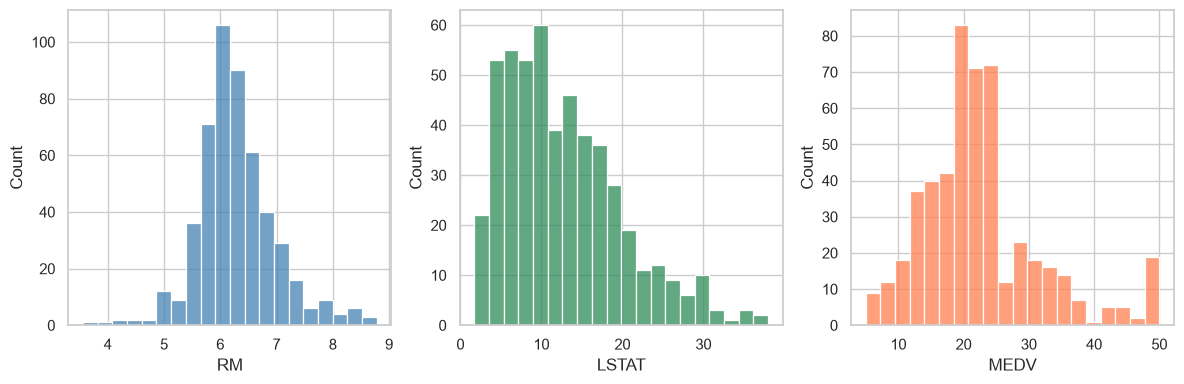

In [ ]:
fig, axis = plt.subplots(1, 3, figsize=(12,4))

for ax, col, color in zip(axis, ["RM", "LSTAT", "MEDV"], ["steelblue", "seagreen", "coral"]):
    sns.histplot(df[col], bins=20, ax=ax, color=color)

plt.tight_layout()
plt.show()

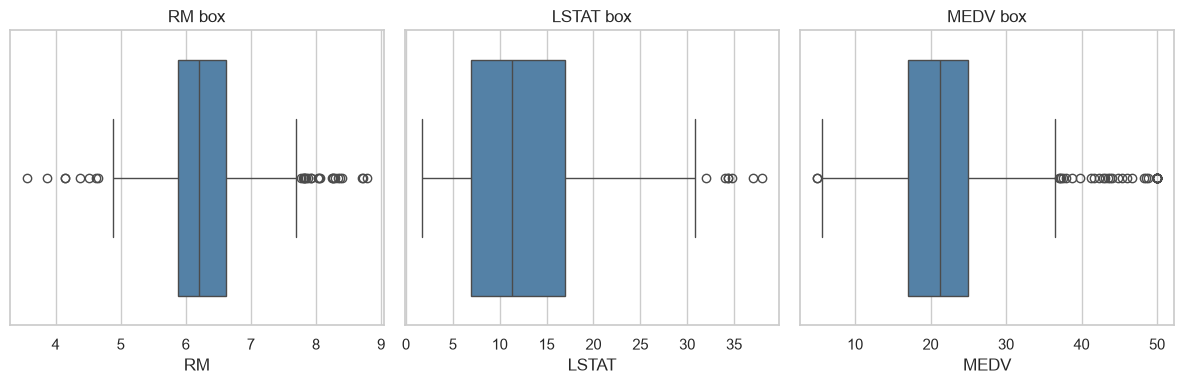

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["RM", "LSTAT", "MEDV"]):
    sns.boxplot(x=df[col], ax=ax, color="steelblue")
    ax.set_title(col + " box")

plt.tight_layout()
plt.show()

LSTAT and MEDV often look skewed. Real life piles up at one end. Mean is dramatic. Median is honest.

### 7. Countplot with hue

In [28]:
df['Pricey'] = (df['MEDV'] > df['MEDV'].median()).astype(int)
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV,Pricey
0,0.00632,18.0,2.31,0,0.538,6.575,4.0900,1,296.0,15.3,4.98,24.0,1
1,0.02731,0.0,7.07,0,0.469,6.421,4.9671,2,242.0,17.8,9.14,21.6,1
2,0.02729,0.0,7.07,0,0.469,7.185,4.9671,2,242.0,17.8,4.03,34.7,1
3,0.03237,0.0,2.18,0,0.458,6.998,6.0622,3,222.0,18.7,2.94,33.4,1
4,0.06905,0.0,2.18,0,0.458,7.147,6.0622,3,222.0,18.7,5.33,36.2,1


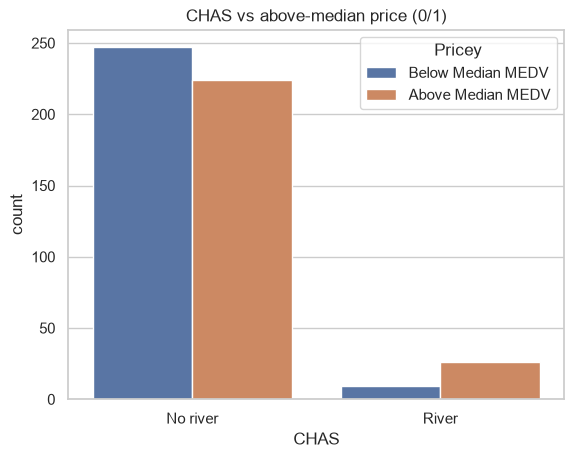

In [32]:
sns.countplot(data=df, x='CHAS', hue='Pricey')
plt.xticks([0, 1], ["No river", "River"])
plt.legend(title='Pricey', labels=["Below Median MEDV", "Above Median MEDV"])
plt.title("CHAS vs above-median price (0/1)")
plt.show()